# YouTube Shorts Virality — Modelling

**Goal:** predict, 6 hours after a Short is published, whether it will be **viral**: in the top 10% of US+CA videos by views at 72 hours.

**Plan:**
1. **Feature engineering:** early performance, engagement, creator, timing, content. Every feature is known 6h after publishing.
2. **Train/test split:**
   - chronological: older videos for training, newer for testing;
   - channels kept separate between training and test;
   - the viral definition and threshold come from training data only;
   - cross-validation inside the training data.
3. **Four experiments** (training population × feature set), all scored on **US+CA** videos:

   | | Baseline: 6h views | All features |
   |---|---|---|
   | **US+CA training** | experiment 1 | experiment 3 |
   | **All-countries training** | experiment 2 | experiment 4 |


Loading and feature code live in `shorts_features.py`, so every notebook builds features the same way.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

import shorts_features as sf

COHORT_END = pd.Timestamp("2026-10-29", tz="UTC")   # videos published before this date
TEST_FRACTION = 0.20      # newest 20% of videos by publish time form the test period
EMBARGO_HOURS = 72        # a training video's 72h outcome must be known before the test period starts
VIRAL_QUANTILE = 0.90     # viral = top 10% of US+CA training videos by 72h views
N_SPLITS, N_REPEATS = 5, 3
RUN_FINAL_TEST = False    # keep False until a model has been chosen with cross-validation

TARGET = "views_72h"
pd.set_option("display.max_columns", 50)

## 1. Feature engineering

| Group | Features (all as of 6h) |
|---|---|
| Early performance | log views at 6h, log views at 3h, view growth 3h → 6h (log ratio) |
| Engagement | log likes, log comments, likes per view, comments per view, likes hidden |
| Creator | log subscribers, channel age, log total channel views, log average views per channel video (historical popularity) |
| Timing | hour posted (US Eastern reference clock, as a 24-hour cycle) |
| Content | duration, number of hashtags, title length, emoji count |

Creator statistics were recorded when the channel was first seen. Missing values (for example hidden likes) are left as NaN for each model to handle.

In [2]:
data = sf.load_data()
table, FEATURE_GROUPS = sf.build_model_table(data)
ALL_FEATURES = [col for cols in FEATURE_GROUPS.values() for col in cols]
BASELINE_FEATURES = ["log_views_6h"]

model_df = (
    table[table["published_at"] < COHORT_END]
    .dropna(subset=["views_6h"])          # a 6h snapshot is required to predict at 6h
    .sort_values("published_at", ignore_index=True)
)
print(f"DATA SNAPSHOT: {data.snapshot_at:%Y-%m-%d %H:%M} UTC ({data.n_snapshot_files} snapshot files)")
print(f"videos with a 72h outcome: {len(table):,}; in cohort with a 6h snapshot: {len(model_df):,} "
      f"({model_df['in_study'].sum():,} US+CA)")
print(f"published {model_df['published_at'].min():%Y-%m-%d %H:%M} → {model_df['published_at'].max():%Y-%m-%d %H:%M} UTC")
display(pd.Series({group: ", ".join(cols) for group, cols in FEATURE_GROUPS.items()}, name="features").to_frame())

DATA SNAPSHOT: 2026-10-26 16:53 UTC (335 snapshot files)
videos with a 72h outcome: 18,170; in cohort with a 6h snapshot: 18,090 (1,956 US+CA)
published 2026-10-12 13:00 → 2026-10-23 18:53 UTC


,features
early performance,"log_views_6h, log_views_3h, view_growth_3_to_6h"
engagement,"log_likes_6h, log_comments_6h, like_rate_6h, c..."
creator,"log_subscribers, channel_age_days, log_channel..."
timing,"pub_hour_sin, pub_hour_cos"
content,"duration_seconds, n_hashtags, title_len, emoji..."


## 2. Train / test split (chronological, channel-separated)

1. **Test period:** the newest `TEST_FRACTION` of videos by publish time. Only its **US+CA** videos are scored.
2. **Embargo:** the `EMBARGO_HOURS` before the test period are not used. In real use, those videos' 72h outcomes would not be known yet.
3. **Channel separation:** training never includes a video from a channel that appears in the test set.
4. **Training (development) set:** everything older than the embargo, minus test channels.
5. **Viral threshold:** the 90th percentile of 72h views among **US+CA training** videos. Test labels use this same threshold.

test period starts 2026-10-21 13:30 UTC; embargo starts 2026-10-18 13:30 UTC
viral threshold (US+CA training videos): 770,242 views at 72h


,all countries,US+CA,US+CA viral
role,,,
training,9289,707,71
embargo (unused),4845,520,52
test channel (unused),338,338,60
test period,3618,391,30


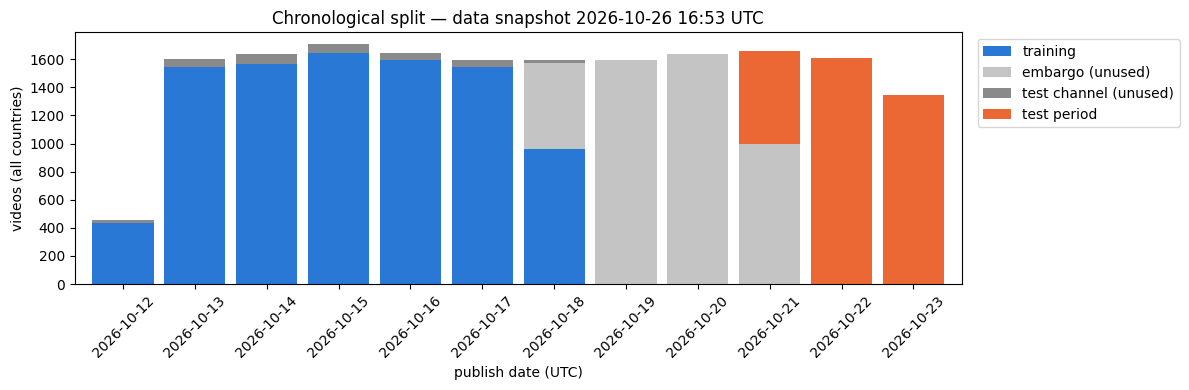

In [3]:
test_start = model_df["published_at"].iloc[int((1 - TEST_FRACTION) * len(model_df))]
embargo_start = test_start - pd.Timedelta(hours=EMBARGO_HOURS)
in_test_period = model_df["published_at"] >= test_start
test = model_df[in_test_period & model_df["in_study"]]

model_df["role"] = np.select(
    [in_test_period, model_df["published_at"] >= embargo_start, model_df["channel_id"].isin(test["channel_id"])],
    ["test period", "embargo (unused)", "test channel (unused)"],
    default="training",
)
dev = model_df[model_df["role"] == "training"].reset_index(drop=True)

threshold = dev.loc[dev["in_study"], TARGET].quantile(VIRAL_QUANTILE)
print(f"test period starts {test_start:%Y-%m-%d %H:%M} UTC; embargo starts {embargo_start:%Y-%m-%d %H:%M} UTC")
print(f"viral threshold (US+CA training videos): {threshold:,.0f} views at 72h")

role_order = ["training", "embargo (unused)", "test channel (unused)", "test period"]
split_table = pd.DataFrame({
    "all countries": model_df["role"].value_counts(),
    "US+CA": model_df.loc[model_df["in_study"], "role"].value_counts(),
    "US+CA viral": model_df.loc[model_df["in_study"]].groupby("role")[TARGET].apply(lambda v: int((v >= threshold).sum())),
}).reindex(role_order).fillna(0).astype(int)
display(split_table)

daily = model_df.groupby([model_df["published_at"].dt.date, "role"]).size().unstack(fill_value=0).reindex(columns=role_order, fill_value=0)
colors = {"training": "#2a78d6", "embargo (unused)": "#c4c4c4", "test channel (unused)": "#8a8a8a", "test period": "#eb6834"}
ax = daily.plot(kind="bar", stacked=True, figsize=(12, 4), width=0.85, color=[colors[r] for r in daily.columns])
ax.set(xlabel="publish date (UTC)", ylabel="videos (all countries)",
       title=f"Chronological split — data snapshot {data.snapshot_at:%Y-%m-%d %H:%M} UTC")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### Feature check on training data

Coverage, typical value, and rank correlation with 72h views for each feature. This uses **training data only**, so nothing about the test period influences feature choices.

In [4]:
dev_us = dev[dev["in_study"]]
group_of = {col: group for group, cols in FEATURE_GROUPS.items() for col in cols}
feature_check = pd.DataFrame({
    "group": pd.Series(group_of),
    "non-missing % (training)": dev[ALL_FEATURES].notna().mean().mul(100),
    "median (training)": dev[ALL_FEATURES].median(),
    "Spearman with 72h views (US+CA training)": dev_us[ALL_FEATURES].corrwith(dev_us[TARGET], method="spearman"),
}).loc[ALL_FEATURES]
display(feature_check.round(3))

,group,non-missing % (training),median (training),Spearman with 72h views (US+CA training)
log_views_6h,early performance,100.000,10.026,0.818
log_views_3h,early performance,99.225,8.970,0.743
view_growth_3_to_6h,early performance,99.225,0.782,0.417
log_likes_6h,engagement,87.480,6.150,0.744
log_comments_6h,engagement,99.365,1.609,0.398
like_rate_6h,engagement,87.480,0.023,-0.003
comment_rate_6h,engagement,99.365,0.000,-0.039
likes_hidden_6h,engagement,100.000,0.000,0.007
log_subscribers,creator,100.000,12.468,0.242
channel_age_days,creator,100.000,1297.243,-0.137


## 3. Cross-validation folds

`StratifiedGroupKFold` on the training set, grouped by channel (a creator's videos never sit in both training and validation) and balanced on the viral rate, repeated `N_REPEATS` times.

All four experiments use **the same folds**, so they can be compared fold by fold:
- each fold's viral threshold is recomputed from that fold's US+CA training videos;
- validation is always the fold's US+CA videos;
- only the training rows change between experiments.

In [5]:
y_dev = dev[TARGET] >= threshold   # only used to balance the folds

def cv_folds(n_repeats=N_REPEATS):
    # Yields (repeat, fold, training rows [all countries], US+CA validation rows, fold threshold).
    for repeat in range(n_repeats):
        folds = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=repeat)
        for fold, (train_idx, val_idx) in enumerate(folds.split(dev, y_dev, groups=dev["channel_id"])):
            train, val = dev.iloc[train_idx], dev.iloc[val_idx]
            fold_threshold = train.loc[train["in_study"], TARGET].quantile(VIRAL_QUANTILE)
            yield repeat, fold, train, val[val["in_study"]], fold_threshold

fold_table = pd.DataFrame([
    {"repeat": r, "fold": f,
     "train: all countries": len(train), "train: US+CA": int(train["in_study"].sum()),
     "train US+CA viral": int((train.loc[train["in_study"], TARGET] >= t).sum()),
     "validation: US+CA": len(val), "validation viral": int((val[TARGET] >= t).sum()),
     "threshold": round(t)}
    for r, f, train, val, t in cv_folds()
])
display(fold_table[fold_table["repeat"] == 0])
display(fold_table.drop(columns=["repeat", "fold"]).agg(["min", "mean", "max"]).round(0))

,repeat,fold,train: all countries,train: US+CA,train US+CA viral,validation: US+CA,validation viral,threshold
0,0,0,7445,548,55,159,20,708306
1,0,1,7446,558,56,149,11,800609
2,0,2,7486,578,58,129,18,687503
3,0,3,7337,581,59,126,5,840042
4,0,4,7442,563,57,144,16,752969


,train: all countries,train: US+CA,train US+CA viral,validation: US+CA,validation viral,threshold
min,7337.0,532.0,54.0,121.0,5.0,631014.0
mean,7431.0,566.0,57.0,141.0,14.0,756982.0
max,7532.0,586.0,59.0,175.0,25.0,866102.0


## 4. Experiments

| # | Training population | Features |
|---|---|---|
| 1 | US+CA | baseline: log views at 6h |
| 2 | All countries | baseline: log views at 6h |
| 3 | US+CA | all features |
| 4 | All countries | all features |

All four are scored on the same US+CA validation folds:
- experiments 1 vs 2 and 3 vs 4 show whether training on all countries helps;
- experiments 1 vs 3 and 2 vs 4 show what the extra features add beyond 6h views.

In [6]:
EXPERIMENTS = {
    "1. US+CA, baseline": ("US+CA", BASELINE_FEATURES),
    "2. All countries, baseline": ("All countries", BASELINE_FEATURES),
    "3. US+CA, all features": ("US+CA", ALL_FEATURES),
    "4. All countries, all features": ("All countries", ALL_FEATURES),
}

def training_rows(frame, population):
    return frame[frame["in_study"]] if population == "US+CA" else frame

display(pd.DataFrame([
    {"experiment": name, "training population": population, "features": len(features),
     "training videos": len(training_rows(dev, population)),
     "training viral": int((training_rows(dev, population)[TARGET] >= threshold).sum())}
    for name, (population, features) in EXPERIMENTS.items()
]).set_index("experiment"))

,training population,features,training videos,training viral
experiment,,,,
"1. US+CA, baseline",US+CA,1,707,71
"2. All countries, baseline",All countries,1,9289,854
"3. US+CA, all features",US+CA,18,707,71
"4. All countries, all features",All countries,18,9289,854


### Evaluation harness (ready for models)

`run_experiments(MODELS)` trains every model in every experiment on every fold, and scores it on the fold's US+CA validation videos.

**Metrics:**
- **PR-AUC:** main metric; its random baseline is the viral rate (~0.10).
- **ROC-AUC.**
- **precision@10% / recall@10%:** flag the top 10% of scores and check them against the true labels.

Each model must be an sklearn-style classifier with `predict_proba`. Models that cannot handle NaN need an imputer in a pipeline; XGBoost and recent scikit-learn trees accept NaN directly.

In [7]:
METRICS = ["PR-AUC", "ROC-AUC", "precision@10%", "recall@10%"]

def score(y_true, scores):
    flagged = scores >= np.quantile(scores, VIRAL_QUANTILE)
    hits = (flagged & y_true).sum()
    return {"PR-AUC": average_precision_score(y_true, scores), "ROC-AUC": roc_auc_score(y_true, scores),
            "precision@10%": hits / flagged.sum(), "recall@10%": hits / y_true.sum()}

def run_experiments(models, experiments=EXPERIMENTS, n_repeats=N_REPEATS):
    rows = []
    for repeat, fold, train, val, fold_threshold in cv_folds(n_repeats):
        y_val = (val[TARGET] >= fold_threshold).to_numpy()
        for experiment, (population, features) in experiments.items():
            train_exp = training_rows(train, population)
            y_train = train_exp[TARGET] >= fold_threshold
            for model_name, model in models.items():
                fitted = clone(model).fit(train_exp[features], y_train)
                rows.append({"experiment": experiment, "model": model_name, "repeat": repeat, "fold": fold,
                             **score(y_val, fitted.predict_proba(val[features])[:, 1])})
    return pd.DataFrame(rows)

def summarize(results):
    stats = results.groupby(["experiment", "model"], sort=False)[METRICS].agg(["mean", "std"])
    return pd.DataFrame({m: stats[(m, "mean")].map("{:.3f}".format) + " ± " + stats[(m, "std")].map("{:.3f}".format)
                         for m in METRICS})

In [8]:
# Next step: add logistic regression, decision tree, random forest and XGBoost here, e.g.
#   from sklearn.linear_model import LogisticRegression
#   from sklearn.impute import SimpleImputer
#   from sklearn.pipeline import make_pipeline
#   from sklearn.preprocessing import StandardScaler
#   MODELS["Logistic regression"] = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
#                                                 StandardScaler(), LogisticRegression(max_iter=2000))
MODELS = {}

if MODELS:
    cv_results = run_experiments(MODELS)
    display(summarize(cv_results))
else:
    print("No models yet: add them to MODELS to run the four experiments.")

No models yet: add them to MODELS to run the four experiments.


## 5. Final test (run once, at the end)

After choosing one model and one experiment with cross-validation, set `RUN_FINAL_TEST = True` and run once on the frozen data copy. The model is refit on the full training set and scored on the held-out US+CA test videos. Do not change the model after looking at the test result.

In [9]:
def final_test(model, experiment):
    population, features = EXPERIMENTS[experiment]
    train = training_rows(dev, population)
    fitted = clone(model).fit(train[features], train[TARGET] >= threshold)
    y_test = (test[TARGET] >= threshold).to_numpy()
    print(f"Final test — data snapshot {data.snapshot_at:%Y-%m-%d %H:%M} UTC; {len(test):,} US+CA videos, {y_test.sum()} viral")
    return score(y_test, fitted.predict_proba(test[features])[:, 1])

if RUN_FINAL_TEST:
    CHOSEN_MODEL, CHOSEN_EXPERIMENT = "Logistic regression", "4. All countries, all features"   # set after CV
    display(pd.Series(final_test(MODELS[CHOSEN_MODEL], CHOSEN_EXPERIMENT)).round(3).to_frame("test"))
else:
    print("Final test is locked until a model is chosen with cross-validation.")

Final test is locked until a model is chosen with cross-validation.
